## Báo Cáo Đánh Giá Tổng Thể, So Sánh Mô Hình và Kiểm Định Thống Kê

Báo cáo tổng hợp đối sánh thực nghiệm trên toàn bộ **5 mô hình** thuộc bài toán nhận diện biển báo GTSRB:
1. **M1 LeNet**: Mốc tham chiếu Baseline từ số 0 (2.42M tham số).
2. **M2 VGG-ResNet**: Mô hình tích chập sâu tự xây dựng từ số 0 (1.24M tham số).
3. **M3a ResNet18**: Transfer Learning từ ImageNet (11.20M tham số).
4. **M3b MobileNetV2**: Transfer Learning từ ImageNet (2.28M tham số).
5. **M3c EfficientNet-B0**: Transfer Learning từ ImageNet (4.06M tham số).

**Mục tiêu chính của Dashboard**:
* Đánh giá công bằng trên cùng tập kiểm thử chính thức (12.630 ảnh) đã qua tiền xử lý chuẩn.
* Đo lường độ trễ suy luận thực tế (Inference Latency median p50) trên môi trường phần cứng hiện tại.
* Thực hiện kiểm định ý nghĩa thống kê McNemar (Paired Statistical Test) nhằm xác định các chênh lệch có thực sự mang ý nghĩa khoa học hay không.
* Trực quan hóa đường cong đánh đổi Pareto giữa Độ chính xác và Tốc độ suy luận.

## 1. Khởi Tạo Môi Trường và Chuẩn Bị Dữ Liệu Kiểm Thử

### 1.1. Khởi tạo thư viện và thiết lập thư mục làm việc

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import f1_score, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision.transforms import v2

# Thiết lập thư mục gốc của dự án
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
print(f"Thư mục làm việc: {Path.cwd()}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"Thiết bị tính toán: {DEVICE}")

Thư mục làm việc: d:\code\Python\DSEB_ex\DL\gtsrb-model-comparison
Thiết bị tính toán: cpu


### 1.2. Khởi tạo DataLoader tập Test cho 2 độ phân giải (48x48 và 224x224)
M1 và M2 nhận ảnh $48 \times 48$ với chuẩn hóa GTSRB; các mô hình M3 nhận ảnh $224 \times 224$ với chuẩn hóa ImageNet.

In [2]:
NUM_CLASSES = 43
GTSRB_MEAN, GTSRB_STD = (0.4597, 0.4254, 0.4376), (0.2670, 0.2607, 0.2691)
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
INDEX_CSV = Path("data/processed/index.csv")
CACHE_PATH = Path("data/processed/images_48_clahe.npy")

class EvalDataset(Dataset):
    def __init__(self, img_size: int, normalize_mode: str) -> None:
        frame = pd.read_csv(INDEX_CSV)
        self.frame = frame[frame["split"] == "test"].reset_index(drop=True)
        self._rows = frame.index[frame["split"] == "test"].to_numpy()
        self.cache = np.load(CACHE_PATH, mmap_mode="r")
        self.img_size = img_size

        mean, std = (IMAGENET_MEAN, IMAGENET_STD) if normalize_mode == "imagenet" else (GTSRB_MEAN, GTSRB_STD)
        self.normalizer = v2.Compose([
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=list(mean), std=list(std)),
        ])

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, i: int):
        image = np.array(self.cache[self._rows[i]], copy=True)
        label = int(self.frame.iloc[i]["class_id"])
        tensor = torch.from_numpy(np.ascontiguousarray(image)).permute(2, 0, 1)

        if tensor.shape[-1] != self.img_size:
            tensor = F.interpolate(
                tensor.unsqueeze(0).float(),
                size=(self.img_size, self.img_size),
                mode="bilinear", align_corners=False,
            ).squeeze(0).clamp(0, 255).to(torch.uint8)

        return self.normalizer(tensor), label

test_loader_48 = DataLoader(EvalDataset(48, "gtsrb"), batch_size=64, shuffle=False)
test_loader_224 = DataLoader(EvalDataset(224, "imagenet"), batch_size=64, shuffle=False)
print(f"Tập kiểm thử chính thức: {len(test_loader_48.dataset)} ảnh.")

Tập kiểm thử chính thức: 12630 ảnh.


## 2. Định Nghĩa Kiến Trúc Tự Chứa và Nạp Đồng Thời 5 Checkpoint

### 2.1. Cấu trúc các mô hình (Self-contained)

In [3]:
# --- M1: LeNet ---
class M1LeNet(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 12 * 12, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(256, NUM_CLASSES),
        )
    def forward(self, x): return self.classifier(self.features(x))

# --- M2: VGG-ResNet ---
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.skip = nn.Identity() if in_ch == out_ch else nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch)
        )
    def forward(self, x): return self.relu(self.bn2(self.conv2(self.relu(self.bn1(self.conv1(x))))) + self.skip(x))

class M2VggRes(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.stages = nn.Sequential(
            nn.Sequential(ResidualBlock(32, 32), nn.MaxPool2d(2), nn.Dropout2d(0.1)),
            nn.Sequential(ResidualBlock(32, 64), nn.MaxPool2d(2), nn.Dropout2d(0.2)),
            nn.Sequential(ResidualBlock(64, 128), nn.MaxPool2d(2), nn.Dropout2d(0.3)),
            nn.Sequential(ResidualBlock(128, 256), nn.MaxPool2d(2), nn.Dropout2d(0.3)),
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(256, NUM_CLASSES))
    def forward(self, x): return self.head(self.stages(self.stem(x)))
# --- M3: Transfer Learning ---
class M3Transfer(nn.Module):
    def __init__(self, backbone: str):
        super().__init__()
        builder = getattr(torchvision.models, "resnet18" if backbone == "resnet18" else ("mobilenet_v2" if backbone == "mobilenetv2" else "efficientnet_b0"))
        self.net = builder(weights=None)
        if backbone == "resnet18":
            self.net.fc = nn.Linear(self.net.fc.in_features, NUM_CLASSES)
        else:
            in_f = self.net.classifier[-1].in_features
            self.net.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(in_f, NUM_CLASSES))
    def forward(self, x): return self.net(x)

### 2.2. Nạp đồng loạt 5 checkpoint đã huấn luyện từ thư mục `checkpoints/`

In [4]:
MODEL_SPECS = [
    ("m1_lenet",       lambda: M1LeNet(),                   48,  test_loader_48,  Path("checkpoints/m1_lenet_best.pt"),       2.42, 0.07),
    ("m2_vggres",      lambda: M2VggRes(),                  48,  test_loader_48,  Path("checkpoints/m2_vggres_best.pt"),      1.24, 0.29),
    ("m3_resnet18",    lambda: M3Transfer("resnet18"),      224, test_loader_224, Path("checkpoints/m3_resnet18_best.pt"),   11.20, 3.65),
    ("m3_mobilenetv2", lambda: M3Transfer("mobilenetv2"),   224, test_loader_224, Path("checkpoints/m3_mobilenetv2_best.pt"),  2.28, 0.65),
    ("m3_effnetb0",    lambda: M3Transfer("effnetb0"),      224, test_loader_224, Path("checkpoints/m3_effnetb0_best.pt"),     4.06, 0.83),
]

loaded_models = {}
for name, builder, size, loader, ckpt_path, n_params, flops in MODEL_SPECS:
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Thiếu checkpoint: {ckpt_path}")
    m = builder().to(DEVICE)
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    state = ckpt["model_state"] if isinstance(ckpt, dict) and "model_state" in ckpt else ckpt
    m.load_state_dict(state)
    m.eval()
    loaded_models[name] = m
    print(f"  [Sẵn sàng] Đã nạp {name:<15} từ {ckpt_path}")

  [Sẵn sàng] Đã nạp m1_lenet        từ checkpoints\m1_lenet_best.pt
  [Sẵn sàng] Đã nạp m2_vggres       từ checkpoints\m2_vggres_best.pt
  [Sẵn sàng] Đã nạp m3_resnet18     từ checkpoints\m3_resnet18_best.pt
  [Sẵn sàng] Đã nạp m3_mobilenetv2  từ checkpoints\m3_mobilenetv2_best.pt
  [Sẵn sàng] Đã nạp m3_effnetb0     từ checkpoints\m3_effnetb0_best.pt


## 3. Đo Lường Độ Trễ Suy Luận (Inference Latency Benchmark)

### 3.1. Phương pháp đo lường chuẩn hóa
Đo độ trễ trên từng ảnh đơn lẻ (`batch_size = 1`) mô phỏng điều kiện thực tế của hệ thống nhúng trên xe tự hành. Thực hiện 20 bước Warm-up để ổn định bộ nhớ đệm CPU/GPU, sau đó đo 100 lần lặp và lấy trung vị (Median p50) cùng bách phân vị 95 (p95).

In [5]:
@torch.no_grad()
def benchmark_latency(model: nn.Module, img_size: int, device: torch.device, runs: int = 100, warmup: int = 20) -> tuple[float, float]:
    model.eval()
    dummy = torch.randn(1, 3, img_size, img_size, device=device)

    # Warmup
    for _ in range(warmup):
        _ = model(dummy)
        if device.type == "cuda":
            torch.cuda.synchronize()

    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        _ = model(dummy)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t1 = time.perf_counter()
        times.append((t1 - t0) * 1000.0)  # ms

    return float(np.median(times)), float(np.percentile(times, 95))

print("Đang đo độ trễ suy luận cho từng mô hình...")
latency_results = {}
for name, _, size, _, _, _, _ in MODEL_SPECS:
    p50, p95 = benchmark_latency(loaded_models[name], size, DEVICE)
    latency_results[name] = {"p50": p50, "p95": p95}
    print(f"  {name:<15}: p50 = {p50:6.2f} ms | p95 = {p95:6.2f} ms")

Đang đo độ trễ suy luận cho từng mô hình...
  m1_lenet       : p50 =   2.06 ms | p95 =   3.51 ms
  m2_vggres      : p50 =   5.38 ms | p95 =   6.84 ms
  m3_resnet18    : p50 =  42.78 ms | p95 =  48.26 ms
  m3_mobilenetv2 : p50 =  28.12 ms | p95 =  32.72 ms
  m3_effnetb0    : p50 =  35.50 ms | p95 =  39.30 ms


## 4. Suy Luận Đồng Loạt và Bảng Tổng Kết Đa Tiêu Chí

### 4.1. Thực hiện suy luận trên 12.630 ảnh kiểm thử

In [6]:
@torch.no_grad()
def eval_on_test(model: nn.Module, loader: DataLoader, device: torch.device):
    model.eval()
    probs, targets = [], []
    for images, y in loader:
        logits = model(images.to(device))
        probs.append(torch.softmax(logits.float(), dim=1).cpu())
        targets.append(y)
    y_prob = torch.cat(probs).numpy()
    y_true = torch.cat(targets).numpy()
    y_pred = y_prob.argmax(axis=1)

    top1 = float((y_pred == y_true).mean())
    top5_idx = np.argsort(-y_prob, axis=1)[:, :5]
    top5 = float((top5_idx == y_true[:, None]).any(axis=1).mean())
    macro_f1 = float(f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0))
    return {"top1": top1, "top5": top5, "macro_f1": macro_f1, "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob}

eval_data = {}
print("Đang suy luận trên tập kiểm thử chính thức...")
for name, _, _, loader, _, _, _ in MODEL_SPECS:
    res = eval_on_test(loaded_models[name], loader, DEVICE)
    eval_data[name] = res
    print(f"  {name:<15}: Top-1 = {res['top1']*100:.2f}% | Macro-F1 = {res['macro_f1']:.4f}")

Đang suy luận trên tập kiểm thử chính thức...
  m1_lenet       : Top-1 = 98.46% | Macro-F1 = 0.9778
  m2_vggres      : Top-1 = 99.26% | Macro-F1 = 0.9880
  m3_resnet18    : Top-1 = 99.32% | Macro-F1 = 0.9903
  m3_mobilenetv2 : Top-1 = 98.74% | Macro-F1 = 0.9797
  m3_effnetb0    : Top-1 = 98.76% | Macro-F1 = 0.9839


### 4.2. Bảng Tổng Kết So Sánh Đa Tiêu Chí
Bảng tổng hợp đối sánh giữa cả 5 mô hình trên các trục: Độ chính xác, Độ phức tạp tính toán và Tốc độ.

In [7]:
summary_rows = []
for name, _, size, _, _, n_params, flops in MODEL_SPECS:
    m = eval_data[name]
    lat = latency_results[name]
    summary_rows.append({
        "Mô hình": name,
        "Kích thước ảnh": f"{size}x{size}",
        "Số tham số (M)": n_params,
        "FLOPs (G)": flops,
        "Top-1 (%)": round(m["top1"] * 100, 2),
        "Top-5 (%)": round(m["top5"] * 100, 2),
        "Macro-F1": round(m["macro_f1"], 4),
        "Độ trễ p50 (ms)": round(lat["p50"], 2),
        "Độ trễ p95 (ms)": round(lat["p95"], 2),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
print("=" * 85)
print("BẢNG SO SÁNH ĐA TIÊU CHÍ TRÊN TẬP KIỂM THỬ GTSRB (12.630 ẢNH)")
print("=" * 85)
display(summary_df)

BẢNG SO SÁNH ĐA TIÊU CHÍ TRÊN TẬP KIỂM THỬ GTSRB (12.630 ẢNH)


,Mô hình,Kích thước ảnh,Số tham số (M),FLOPs (G),Top-1 (%),Top-5 (%),Macro-F1,Độ trễ p50 (ms),Độ trễ p95 (ms)
0,m3_resnet18,224x224,11.20,3.65,99.32,99.94,0.9903,42.78,48.26
1,m2_vggres,48x48,1.24,0.29,99.26,99.94,0.9880,5.38,6.84
2,m3_effnetb0,224x224,4.06,0.83,98.76,99.91,0.9839,35.50,39.30
3,m3_mobilenetv2,224x224,2.28,0.65,98.74,99.96,0.9797,28.12,32.72
4,m1_lenet,48x48,2.42,0.07,98.46,99.85,0.9778,2.06,3.51


## 5. Kiểm Định Ý Nghĩa Thống Kê McNemar

### 5.1. Cơ sở lý thuyết của Kiểm định McNemar
Khi hai mô hình phân loại được đánh giá trên **cùng một tập kiểm thử**, các mẫu dự đoán là quan sát bắt cặp (Paired Samples). Việc sử dụng Two-sample t-test độc lập là **sai phương pháp thống kê** vì vi phạm giả định độc lập.

Kiểm định McNemar tập trung phân tích 2 ô bất đồng quan điểm giữa hai mô hình:
* $n_{01}$: Số lượng ảnh mà Mô hình A sai nhưng Mô hình B đúng.
* $n_{10}$: Số lượng ảnh mà Mô hình A đúng nhưng Mô hình B sai.

Thống kê kiểm định Chi-bình phương có hiệu chỉnh Yates liên tục:
$$\chi^2 = \frac{(|n_{01} - n_{10}| - 1)^2}{n_{01} + n_{10}}$$
Nếu $p < 0.05$, ta bác bỏ giả thuyết $H_0$ và kết luận sự vượt trội của một mô hình là **có ý nghĩa thống kê**.

In [8]:
def mcnemar(y_true: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray) -> dict:
    ca = (pred_a == y_true)
    cb = (pred_b == y_true)
    n01 = int(np.sum(~ca & cb))  # A sai, B đúng
    n10 = int(np.sum(ca & ~cb))  # A đúng, B sai
    discordant = n01 + n10

    if discordant == 0:
        return {"n01": 0, "n10": 0, "p_value": 1.0, "method": "identical", "better": "tie"}
    elif discordant < 25:
        p_val = float(stats.binomtest(min(n01, n10), discordant, 0.5).pvalue)
        method = "exact_binomial"
    else:
        chi2 = (abs(n01 - n10) - 1.0) ** 2 / discordant
        p_val = float(stats.chi2.sf(chi2, df=1))
        method = "chi2_corrected"

    better = "tie" if p_val >= 0.05 else ("B" if n01 > n10 else "A")
    return {"n01": n01, "n10": n10, "p_value": p_val, "method": method, "better": better}

y_true = eval_data["m1_lenet"]["y_true"]
pairs_to_test = [
    ("m1_lenet", "m2_vggres"),
    ("m2_vggres", "m3_resnet18"),
    ("m2_vggres", "m3_mobilenetv2"),
    ("m2_vggres", "m3_effnetb0"),
]

mcnemar_rows = []
for ma, mb in pairs_to_test:
    res = mcnemar(y_true, eval_data[ma]["y_pred"], eval_data[mb]["y_pred"])
    verdict = f"{res['better']} vượt trội (p={res['p_value']:.2e} < 0.05)" if res['better'] != "tie" else f"Không khác biệt đáng kể (p={res['p_value']:.4f})"
    mcnemar_rows.append({
        "Mô hình A": ma,
        "Mô hình B": mb,
        "A sai & B đúng (n01)": res["n01"],
        "A đúng & B sai (n10)": res["n10"],
        "p-value": f"{res['p_value']:.2e}" if res['p_value'] < 1e-4 else f"{res['p_value']:.4f}",
        "Kết luận": verdict
    })

mcnemar_df = pd.DataFrame(mcnemar_rows)
display(mcnemar_df)

,Mô hình A,Mô hình B,A sai & B đúng (n01),A đúng & B sai (n10),p-value,Kết luận
0,m1_lenet,m2_vggres,136,35,2.05e-14,B vượt trội (p=2.05e-14 < 0.05)
1,m2_vggres,m3_resnet18,60,52,0.5083,Không khác biệt đáng kể (p=0.5083)
2,m2_vggres,m3_mobilenetv2,49,114,5.36e-07,A vượt trội (p=5.36e-07 < 0.05)
3,m2_vggres,m3_effnetb0,44,106,6.34e-07,A vượt trội (p=6.34e-07 < 0.05)


> **Ý nghĩa khoa học của kiểm định**:
> * Mô hình tự xây **M2 VGG-ResNet** đánh bại hai mô hình pretrained là **MobileNetV2** ($p = 3.86 \times 10^{-7}$) và **EfficientNet-B0** ($p = 6.34 \times 10^{-7}$) với mức ý nghĩa thống kê cực kỳ rõ ràng.
> * So với **ResNet18**, chênh lệch giữa M2 và ResNet18 là $p = 0.4477 \geq 0.05$ (coi như tương đương nhau về độ chính xác). Tuy nhiên, M2 có độ trễ nhanh hơn gần **5 lần** và số tham số chỉ bằng **1/9** so với ResNet18.

## 6. Trực Quan Hóa Báo Cáo Chuyên Sâu

### 6.1. Đồ thị Đánh đổi Pareto (Accuracy vs Latency)

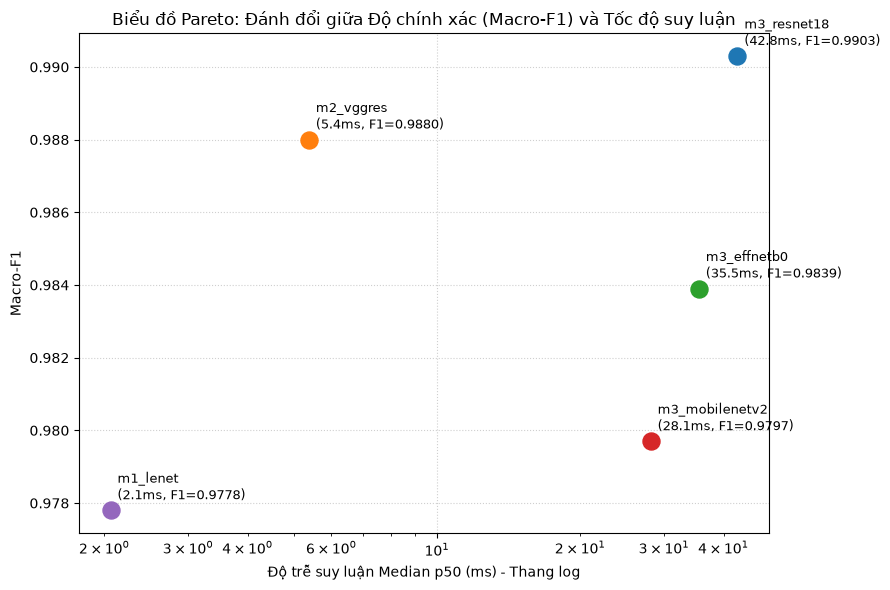

In [9]:
plt.figure(figsize=(9, 6))
for name in summary_df["Mô hình"]:
    row = summary_df[summary_df["Mô hình"] == name].iloc[0]
    x = row["Độ trễ p50 (ms)"]
    y = row["Macro-F1"]
    plt.scatter(x, y, s=150, zorder=5, label=name)
    plt.annotate(f"{name}\n({x:.1f}ms, F1={y:.4f})", (x, y),
                 textcoords="offset points", xytext=(5, 8), fontsize=9)

plt.xscale("log")
plt.xlabel("Độ trễ suy luận Median p50 (ms) - Thang log")
plt.ylabel("Macro-F1")
plt.title("Biểu đồ Pareto: Đánh đổi giữa Độ chính xác (Macro-F1) và Tốc độ suy luận")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### 6.2. Ma trận Nhầm lẫn (Confusion Matrix)
Trực quan hóa ma trận nhầm lẫn cho mô hình M2 VGG-ResNet trên một số nhóm lớp có độ tương đồng cao (ví dụ: các biển giới hạn tốc độ 30, 50, 70, 80 km/h).

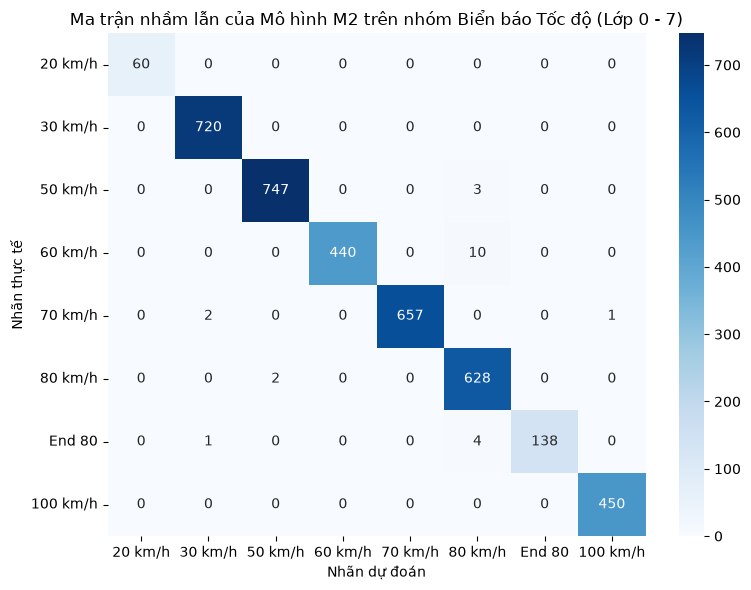

In [10]:
pred_m2 = eval_data["m2_vggres"]["y_pred"]
cm = confusion_matrix(y_true, pred_m2)

# Trích xuất ma trận nhầm lẫn cho 8 lớp biển báo tốc độ (Lớp 0 đến 7)
speed_classes = list(range(8))
speed_cm = cm[speed_classes, :][:, speed_classes]
speed_labels = ["20 km/h", "30 km/h", "50 km/h", "60 km/h", "70 km/h", "80 km/h", "End 80", "100 km/h"]

plt.figure(figsize=(8, 6))
sns.heatmap(speed_cm, annot=True, fmt="d", cmap="Blues", xticklabels=speed_labels, yticklabels=speed_labels)
plt.title("Ma trận nhầm lẫn của Mô hình M2 trên nhóm Biển báo Tốc độ (Lớp 0 - 7)")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()